In [7]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV 
from sklearn.pipeline import Pipeline 
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score 

import warnings 
warnings.filterwarnings('ignore')

# Load & Cleaning Data

In [8]:
df = pd.read_excel("/Users/asyzyni/Desktop/Data Rapih Capstone/Data Capstone Fix BGt.xlsx")
df.head()

,Tanggal,Kelembapan Rata-Rata Udara Harian (%),Temperatur Rata-Rata Harian,Temperatur Maksimum Harian,Temperature Minimum Harian,Angin Rata-Rata Harian (Knot),Curah Hujan,Penyinaran Harian (%),Penguapan Harian (mm),Tekanan Udara Harian (mb)
0,2018-01-01,87.0,27.2,30.2,22.7,2.5,0,0.0,5.4,1008.0
1,2018-01-02,85.0,27.3,32.4,24.2,2.7,0,100.0,3.5,1008.5
2,2018-01-03,77.0,29.7,32.6,24.6,2.1,0,65.0,4.0,1009.3
3,2018-01-04,80.0,28.3,31.8,25.2,2.3,0,43.8,5.2,1009.1
4,2018-01-05,81.0,28.4,32.2,24.3,2.4,6,56.3,2.8,1009.8


mengubah nilai TTU 

In [9]:
df['Curah Hujan'] = df['Curah Hujan'].replace('TTU', 0.01)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1826 entries, 0 to 1825
Data columns (total 10 columns):
 #   Column                                 Non-Null Count  Dtype         
---  ------                                 --------------  -----         
 0   Tanggal                                1826 non-null   datetime64[ns]
 1   Kelembapan Rata-Rata Udara Harian (%)  1826 non-null   float64       
 2   Temperatur Rata-Rata Harian            1826 non-null   float64       
 3   Temperatur Maksimum Harian             1826 non-null   float64       
 4   Temperature Minimum Harian             1826 non-null   float64       
 5   Angin Rata-Rata Harian (Knot)          1826 non-null   float64       
 6   Curah Hujan                            1826 non-null   float64       
 7   Penyinaran Harian (%)                  1826 non-null   float64       
 8   Penguapan Harian (mm)                  1826 non-null   float64       
 9   Tekanan Udara Harian (mb)              1826 non-null   float64 

# EDA

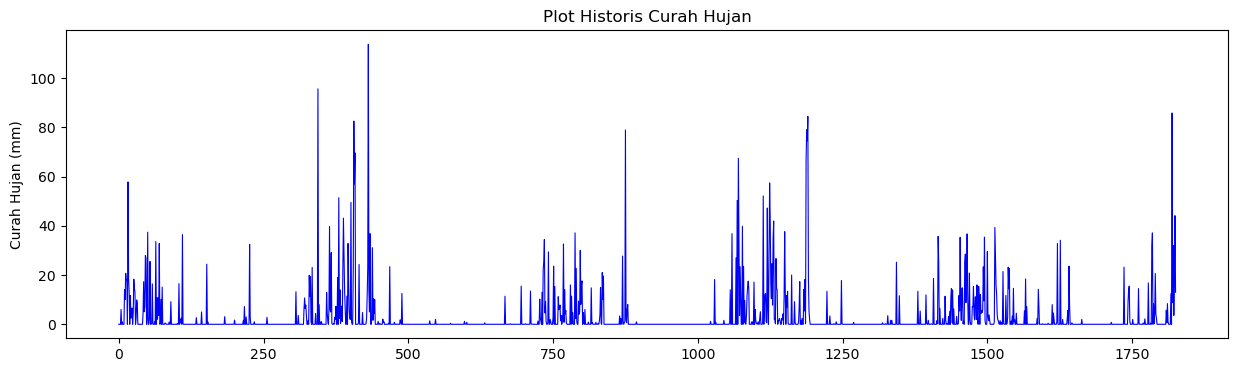

In [11]:
plt.figure(figsize=(15, 4))
plt.plot(df.index, df['Curah Hujan'], color='blue', linewidth=0.8)
plt.title('Plot Historis Curah Hujan')
plt.ylabel('Curah Hujan (mm)')
plt.show()

In [15]:
df['Tanggal'] = pd.to_datetime(df['Tanggal'])
df.set_index('Tanggal', inplace=True)

# Feature Engineering

In [16]:
# Membuat Lag Features (Fitur nilai hari-hari sebelumnya)
df['Curah_Hujan_Lag1'] = df['Curah Hujan'].shift(1)
df['Curah_Hujan_Lag2'] = df['Curah Hujan'].shift(2)
df['Kelembapan_Lag1'] = df['Kelembapan Rata-Rata Udara Harian (%)'].shift(1)

In [13]:
# Membuat Rolling Mean (Rata-rata pergerakan 3 hari terakhir dari curah hujan)
df['Rolling_Mean_3Days'] = df['Curah Hujan'].shift(1).rolling(window=3).mean()

In [17]:
df['Bulan'] = df.index.month
df['Bulan_Sin'] = np.sin(2 * np.pi * df['Bulan'] / 12)
df['Bulan_Cos'] = np.cos(2 * np.pi * df['Bulan'] / 12)

In [18]:
df.dropna(inplace=True)

In [19]:
X = df.drop(columns=['Curah Hujan', 'Bulan'])
y = df['Curah Hujan']